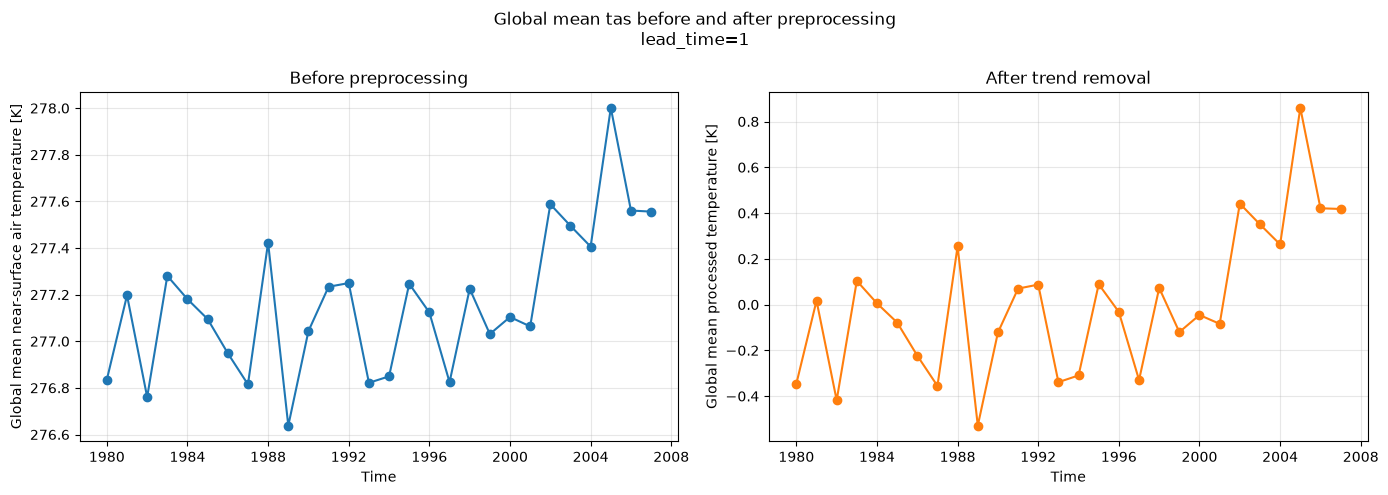

Saved plot to: /fs/site7/eccc/crd/cccma/users/rna002/CCCma-PPP/scripts/module_integration_tests/output.png


In [13]:
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import xarray as xr


CASE_DIR = Path(
    "/fs/site7/eccc/crd/cccma/users/rna002/output/"
    "preprocessing_integration_test_results/cases/model_trend_remover"
)

MODEL_PATH = Path(
    "/space/hall7/sitestore/eccc/crd/cccma/users/rpg002/data/tas/forecast_data/datetime"
)

OUTPUT_PATH = Path("output.png")


pipeline = joblib.load(
    CASE_DIR / "fitted_joblib" / "model_preprocessing_pipeline.joblib"
)

model = xr.open_mfdataset(
    sorted(MODEL_PATH.rglob("*.nc")),
    combine="by_coords",
)

if "year" in model.dims:
    model = model.rename({"year": "time"})

model = model[["tas"]].sel(time=slice("1980", "2007"))

processed = pipeline.transform(model.copy())

lead_time = model["lead_time"].values[0]

before = model["tas"].sel(lead_time=lead_time)

after = processed["tas"].sel(lead_time=lead_time)

before_mean_dims = [dim for dim in ("lat", "lon", "ensembles") if dim in before.dims]

after_mean_dims = [dim for dim in ("lat", "lon", "ensembles") if dim in after.dims]

before = before.mean(before_mean_dims)
after = after.mean(after_mean_dims)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharex=True,
)

before.plot(
    ax=axes[0],
    color="tab:blue",
    marker="o",
)

axes[0].set_title("Before preprocessing")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Global mean near-surface air temperature [K]")
axes[0].grid(True, alpha=0.3)

after.plot(
    ax=axes[1],
    color="tab:orange",
    marker="o",
)

axes[1].set_title("After trend removal")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Global mean processed temperature [K]")
axes[1].grid(True, alpha=0.3)

fig.suptitle(f"Global mean tas before and after preprocessing\nlead_time={lead_time}")

fig.tight_layout()

OUTPUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

fig.savefig(
    OUTPUT_PATH,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(f"Saved plot to: {OUTPUT_PATH.resolve()}")

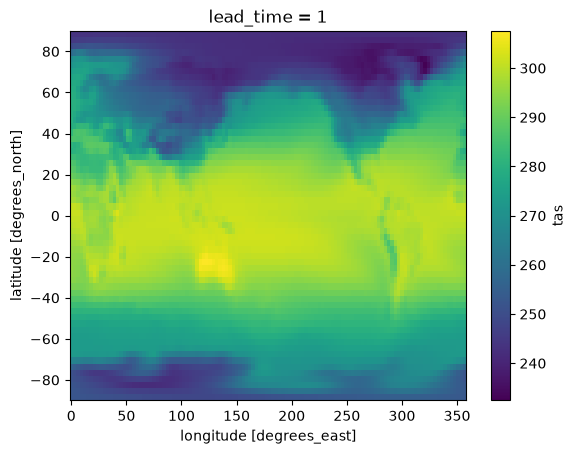

In [12]:
pipeline.get_preprocessors("trend_remover").intercept["tas"][0].plot()

In [ ]:
model = (
    xr.open_mfdataset(
        sorted(MODEL_PATH.rglob("*.nc")),
        combine="by_coords",
    )
    .mean(["lat", "lon"])
    .sel(lead_time=1)
)

if "year" in model.dims:
    model = model.rename({"year": "time"})

pipeline.fit(model)

KeyboardInterrupt: 

In [ ]:
processed = pipeline.transform(model.copy())

lead_time = model["lead_time"].values[0]

before = model["tas"].sel(lead_time=lead_time)

after = processed["tas"].sel(lead_time=lead_time)

before_mean_dims = [dim for dim in ("lat", "lon", "ensembles") if dim in before.dims]

after_mean_dims = [dim for dim in ("lat", "lon", "ensembles") if dim in after.dims]

before = before.mean(before_mean_dims)
after = after.mean(after_mean_dims)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharex=True,
)

before.plot(
    ax=axes[0],
    color="tab:blue",
    marker="o",
)

axes[0].set_title("Before preprocessing")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Global mean near-surface air temperature [K]")
axes[0].grid(True, alpha=0.3)

after.plot(
    ax=axes[1],
    color="tab:orange",
    marker="o",
)

axes[1].set_title("After trend removal")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Global mean processed temperature [K]")
axes[1].grid(True, alpha=0.3)

fig.suptitle(f"Global mean tas before and after preprocessing\nlead_time={lead_time}")

fig.tight_layout()

OUTPUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

fig.savefig(
    OUTPUT_PATH,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(f"Saved plot to: {OUTPUT_PATH.resolve()}")

Raw model dimensions: {'time': 11, 'lead_time': 12, 'lat': 60, 'lon': 120}
Number of plotted time points: 11

Applying Anomalies
Anomalies
  Before slope: -0.003346 K/year
  After slope:  -0.003345 per year
  Saved plot:   /fs/site7/eccc/crd/cccma/users/rna002/CCCma-PPP/scripts/module_integration_tests/preprocessing_plots/model_anomalies_before_after.png

Applying Standardizer
Standardizer
  Before slope: -0.003346 K/year
  After slope:  -0.000164 per year
  Saved plot:   /fs/site7/eccc/crd/cccma/users/rna002/CCCma-PPP/scripts/module_integration_tests/preprocessing_plots/model_standardizer_before_after.png

Applying Normalizer
Normalizer
  Before slope: -0.003346 K/year
  After slope:  -0.000041 per year
  Saved plot:   /fs/site7/eccc/crd/cccma/users/rna002/CCCma-PPP/scripts/module_integration_tests/preprocessing_plots/model_normalizer_before_after.png

Applying Trend remover
Trend remover
  Before slope: -0.003346 K/year
  After slope:  -0.001743 per year
  Saved plot:   /fs/site7/ecc

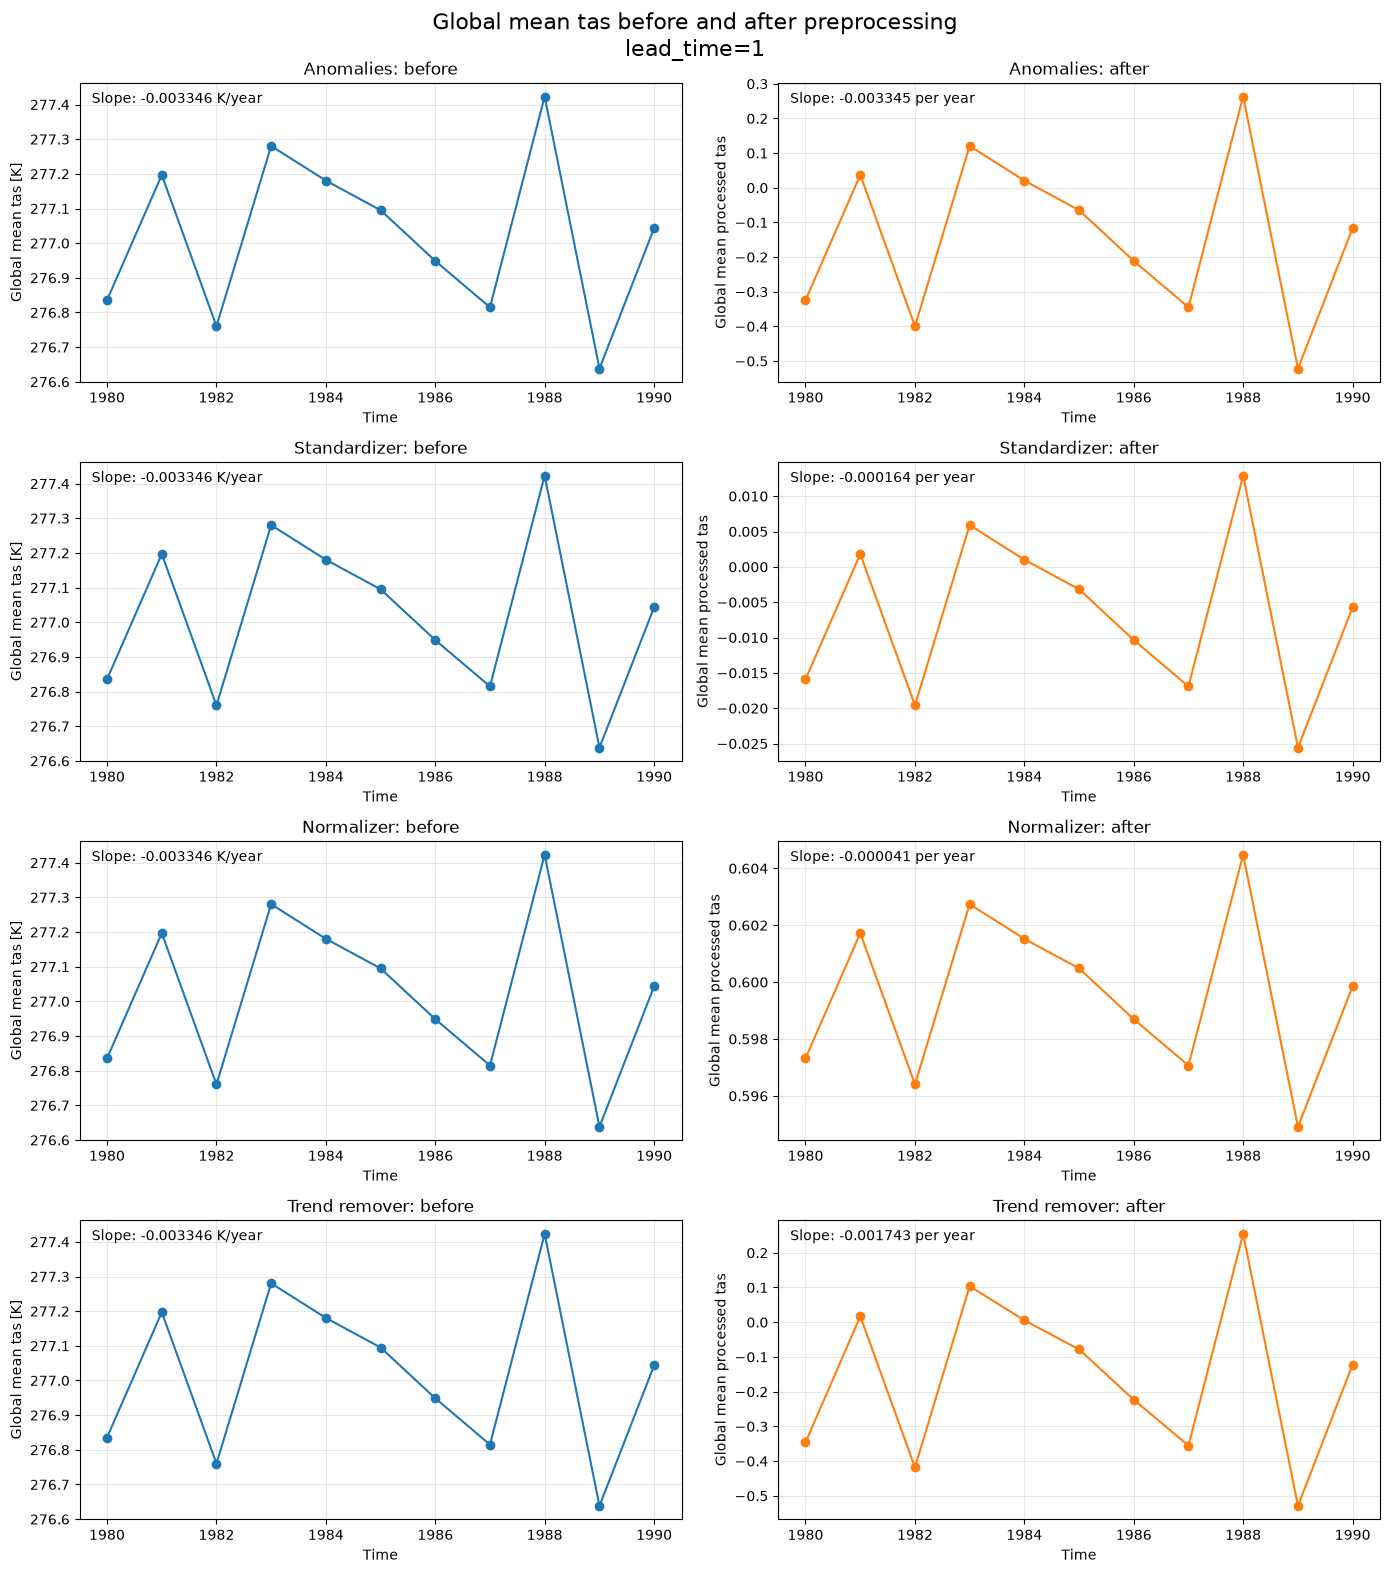


Saved combined plot to: /fs/site7/eccc/crd/cccma/users/rna002/CCCma-PPP/scripts/module_integration_tests/preprocessing_plots/all_preprocessors_before_after.png


In [2]:
from pathlib import Path
from typing import Any

import joblib
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr


RESULTS_DIR = Path(
    "/fs/site7/eccc/crd/cccma/users/rna002/output/"
    "preprocessing_integration_test_results"
)

CASES_DIR = RESULTS_DIR / "cases"

MODEL_PATH = Path(
    "/space/hall7/sitestore/eccc/crd/cccma/users/rpg002/data/tas/forecast_data/datetime"
)

OUTPUT_DIR = Path("preprocessing_plots")

START_YEAR = "1980"
END_YEAR = "1990"
LEAD_TIME = 1

PREPROCESSOR_CASES = {
    "Anomalies": "model_anomalies",
    "Standardizer": "model_standardizer",
    "Normalizer": "model_normalizer",
    "Trend remover": "model_trend_remover",
}


def load_pipeline(case_name: str):
    joblib_path = (
        CASES_DIR / case_name / "fitted_joblib" / "model_preprocessing_pipeline.joblib"
    )

    if not joblib_path.exists():
        raise FileNotFoundError(f"Pipeline not found: {joblib_path}")

    return joblib.load(joblib_path)


def get_global_mean(
    dataset: xr.Dataset,
    *,
    variable_name: str,
    lead_time: int,
) -> xr.DataArray:
    data = dataset[variable_name].sel(lead_time=lead_time)

    mean_dims = [
        dim
        for dim in (
            "lat",
            "lon",
            "ensembles",
            "ensemble",
            "member",
        )
        if dim in data.dims
    ]

    if mean_dims:
        data = data.mean(
            mean_dims,
            keep_attrs=True,
        )

    data = data.squeeze(drop=True)

    if data.dims != ("time",):
        raise AssertionError(f"Expected only the time dimension, got {data.dims}")

    return data.load()


def calculate_slope(
    data: xr.DataArray,
) -> float:
    values = np.asarray(data.values).squeeze()

    valid = np.isfinite(values)

    if valid.sum() < 2:
        return float("nan")

    x = np.arange(
        values.size,
        dtype=float,
    )

    return float(
        np.polyfit(
            x[valid],
            values[valid],
            1,
        )[0]
    )


def make_comparison_plot(
    *,
    display_name: str,
    before: xr.DataArray,
    after: xr.DataArray,
    output_path: Path,
) -> None:
    before_slope = calculate_slope(before)
    after_slope = calculate_slope(after)

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5),
    )

    before.plot(
        ax=axes[0],
        color="tab:blue",
        marker="o",
    )

    axes[0].set_title("Before preprocessing")
    axes[0].set_xlabel("Time")
    axes[0].set_ylabel("Global mean tas [K]")
    axes[0].grid(True, alpha=0.3)

    axes[0].text(
        0.02,
        0.97,
        f"Slope: {before_slope:.6f} K/year",
        transform=axes[0].transAxes,
        verticalalignment="top",
    )

    after.plot(
        ax=axes[1],
        color="tab:orange",
        marker="o",
    )

    axes[1].set_title(f"After {display_name.lower()}")

    axes[1].set_xlabel("Time")
    axes[1].set_ylabel("Global mean processed tas")
    axes[1].grid(True, alpha=0.3)

    axes[1].text(
        0.02,
        0.97,
        f"Slope: {after_slope:.6f} per year",
        transform=axes[1].transAxes,
        verticalalignment="top",
    )

    fig.suptitle(
        f"{display_name}: global mean tas before and after preprocessing\n"
        f"lead_time={LEAD_TIME}"
    )

    fig.tight_layout()

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    fig.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight",
    )

    plt.close(fig)

    print(display_name)
    print(f"  Before slope: {before_slope:.6f} K/year")
    print(f"  After slope:  {after_slope:.6f} per year")
    print(f"  Saved plot:   {output_path.resolve()}")


model_files = sorted(MODEL_PATH.rglob("*.nc"))

if not model_files:
    raise FileNotFoundError(f"No NetCDF files found under {MODEL_PATH}")

model = xr.open_mfdataset(
    model_files,
    combine="by_coords",
)

if "year" in model.dims:
    model = model.rename(
        {
            "year": "time",
        }
    )

if "tas" not in model.data_vars:
    raise KeyError(
        f"'tas' is not present. Available variables: {list(model.data_vars)}"
    )

model = model[["tas"]].sel(
    time=slice(
        START_YEAR,
        END_YEAR,
    ),
    lead_time=slice(
        1,
        12,
    ),
)

if "ensembles" in model.dims:
    model = model.mean(
        "ensembles",
        keep_attrs=True,
    )
elif "ensemble" in model.dims:
    model = model.mean(
        "ensemble",
        keep_attrs=True,
    )
elif "member" in model.dims:
    model = model.mean(
        "member",
        keep_attrs=True,
    )

model = model.load()
raw_model = model.copy(deep=True)

before = get_global_mean(
    raw_model,
    variable_name="tas",
    lead_time=LEAD_TIME,
)

print(f"Raw model dimensions: {dict(raw_model.sizes)}")
print(f"Number of plotted time points: {before.sizes['time']}")

results: dict[str, dict[str, Any]] = {}

for display_name, case_name in PREPROCESSOR_CASES.items():
    print()
    print(f"Applying {display_name}")

    pipeline = load_pipeline(case_name)

    processed = pipeline.transform(raw_model.copy(deep=True))

    after = get_global_mean(
        processed,
        variable_name="tas",
        lead_time=LEAD_TIME,
    )

    output_path = OUTPUT_DIR / f"{case_name}_before_after.png"

    make_comparison_plot(
        display_name=display_name,
        before=before,
        after=after,
        output_path=output_path,
    )

    results[case_name] = {
        "display_name": display_name,
        "pipeline": pipeline,
        "processed": processed,
        "before": before,
        "after": after,
        "before_slope": calculate_slope(before),
        "after_slope": calculate_slope(after),
        "output_path": output_path,
    }


num_cases = len(results)

fig, axes = plt.subplots(
    num_cases,
    2,
    figsize=(14, 4 * num_cases),
    squeeze=False,
)

for row_index, result in enumerate(results.values()):
    display_name = result["display_name"]
    case_before = result["before"]
    case_after = result["after"]
    before_slope = result["before_slope"]
    after_slope = result["after_slope"]

    case_before.plot(
        ax=axes[row_index, 0],
        color="tab:blue",
        marker="o",
    )

    axes[row_index, 0].set_title(f"{display_name}: before")

    axes[row_index, 0].set_xlabel("Time")
    axes[row_index, 0].set_ylabel("Global mean tas [K]")
    axes[row_index, 0].grid(True, alpha=0.3)

    axes[row_index, 0].text(
        0.02,
        0.97,
        f"Slope: {before_slope:.6f} K/year",
        transform=axes[row_index, 0].transAxes,
        verticalalignment="top",
    )

    case_after.plot(
        ax=axes[row_index, 1],
        color="tab:orange",
        marker="o",
    )

    axes[row_index, 1].set_title(f"{display_name}: after")

    axes[row_index, 1].set_xlabel("Time")
    axes[row_index, 1].set_ylabel("Global mean processed tas")
    axes[row_index, 1].grid(True, alpha=0.3)

    axes[row_index, 1].text(
        0.02,
        0.97,
        f"Slope: {after_slope:.6f} per year",
        transform=axes[row_index, 1].transAxes,
        verticalalignment="top",
    )

fig.suptitle(
    f"Global mean tas before and after preprocessing\nlead_time={LEAD_TIME}",
    fontsize=16,
)

fig.tight_layout()

combined_output_path = OUTPUT_DIR / "all_preprocessors_before_after.png"

combined_output_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

fig.savefig(
    combined_output_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print()
print(f"Saved combined plot to: {combined_output_path.resolve()}")